In [19]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import cohen_kappa_score, classification_report, confusion_matrix

# ==========================================
# 1. CONFIGURATION & REPRODUCIBILITY (80+ Target Setup)
# ==========================================
SEED = 2019
np.random.seed(SEED)
tf.random.set_seed(SEED)

CSV_PATH = '/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading.csv' 
IMAGE_DIR = '/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading/DR_grading/' 

# Upgraded Resolution for Fine Details & Smaller Batch Size for GPU RAM
IMG_SIZE = (300, 300)
BATCH_SIZE = 16

print("Initializing Elite EfficientNetB3 Pipeline...")

# ==========================================
# 2. DATA LOADING & STRATIFIED SPLITTING
# ==========================================
df = pd.read_csv(CSV_PATH)
df['diagnosis'] = df['diagnosis'].astype(str)

train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df['diagnosis'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['diagnosis'], random_state=SEED
)

print(f"Training samples:   {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples:       {len(test_df)}")

# ==========================================
# 3. CLASS WEIGHT CALCULATION
# ==========================================
y_train_numeric = train_df['diagnosis'].astype(int).values
classes = np.unique(y_train_numeric)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train_numeric)
class_weights_dict = dict(zip(classes, weights))
print("Computed Class Weights:", class_weights_dict)

# ==========================================
# 4. DATA GENERATORS & PREPROCESSING
# ==========================================
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=25,
    zoom_range=0.25,
    horizontal_flip=True,
    vertical_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1,
    fill_mode='constant'
)

val_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df, directory=IMAGE_DIR, x_col='id_code', y_col='diagnosis',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=True, seed=SEED
)

val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df, directory=IMAGE_DIR, x_col='id_code', y_col='diagnosis',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df, directory=IMAGE_DIR, x_col='id_code', y_col='diagnosis',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

# ==========================================
# 5. MODEL ARCHITECTURE & STAGE 1 (FROZEN)
# ==========================================
base_model = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
base_model.trainable = False  # Initially frozen

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
outputs = Dense(5, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=outputs)

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_list = [
    tf.keras.callbacks.ModelCheckpoint('best_effnet_model.keras', monitor='val_loss', save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1)
]

print("\n--- STAGE 1: Training Classifier Head (EfficientNetB3 Frozen) ---")
history_stage1 = model.fit(
    train_generator, steps_per_epoch=len(train_generator),
    validation_data=val_generator, validation_steps=len(val_generator),
    epochs=6, class_weight=class_weights_dict, callbacks=callbacks_list
)

# ==========================================
# 6. STAGE 2: FULLY UNFREEZING EFFICIENTNETB3
# ==========================================
print("\n--- STAGE 2: Fully Unfreezing EfficientNetB3 for Deep Fine-Tuning ---")
base_model.trainable = True  # Fully unfreeze all blocks

model.compile(
    optimizer=Adam(learning_rate=1e-5),  # Fine-tuning learning rate
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_stage2 = model.fit(
    train_generator, steps_per_epoch=len(train_generator),
    validation_data=val_generator, validation_steps=len(val_generator),
    epochs=10, class_weight=class_weights_dict, callbacks=callbacks_list
)

# ==========================================
# 7. FINAL EVALUATION ON UNTOUCHED TEST SET
# ==========================================
print("\nEvaluating Elite EfficientNetB3 model on the held-out test set...")
model.load_weights('best_effnet_model.keras')

test_generator.reset()
y_pred_probs = model.predict(test_generator, steps=len(test_generator), verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes

qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')
print(f"\n========================================")
print(f"Final Elite Test QWK: {qwk:.4f}")
print(f"========================================")

target_names = ["No DR (0)", "Mild (1)", "Moderate (2)", "Severe (3)", "Proliferative (4)"]
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=target_names))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Initializing Elite EfficientNetB3 Pipeline...
Training samples:   10017
Validation samples: 1252
Test samples:       1253
Computed Class Weights: {np.int64(0): np.float64(0.39964093357271097), np.int64(1): np.float64(3.975), np.int64(2): np.float64(0.5594526668528345), np.int64(3): np.float64(10.6), np.int64(4): np.float64(2.7443835616438355)}
Found 10017 validated image filenames belonging to 5 classes.
Found 1252 validated image filenames belonging to 5 classes.
Found 1253 validated image filenames belonging to 5 classes.
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step

--- STAGE 1: Training Classifier Head (EfficientNetB3 Frozen) ---
Epoch 1/6


E0000 00:00:1794758949.114335     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794758949.284789     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794758952.264673     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794758952.458383     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


454/627 ━━━━━━━━━━━━━━━━━━━━ 1:24 489ms/step - accuracy: 0.2302 - loss: 1.6479

E0000 00:00:1794759195.198173     164 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794759195.380193     164 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794759197.532250     164 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794759197.685461     164 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


627/627 ━━━━━━━━━━━━━━━━━━━━ 0s 518ms/step - accuracy: 0.2445 - loss: 1.6285

E0000 00:00:1794759319.013884     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794759319.220171     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794759321.464991     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794759321.628539     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (3 outputs left out)

E0000 00:00:1794761078.848879     163 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794761079.000791     163 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794761082.427521     163 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


627/627 ━━━━━━━━━━━━━━━━━━━━ 0s 571ms/step - accuracy: 0.3285 - loss: 1.4064
Epoch 1: val_loss did not improve from 1.09557
627/627 ━━━━━━━━━━━━━━━━━━━━ 519s 617ms/step - accuracy: 0.3739 - loss: 1.3649 - val_accuracy: 0.5232 - val_loss: 1.1824 - learning_rate: 1.0000e-05
Epoch 2/10
627/627 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.4504 - loss: 1.1942
Epoch 2: val_loss improved from 1.09557 to 1.05425, saving model to best_effnet_model.keras

Epoch 2: finished saving model to best_effnet_model.keras
627/627 ━━━━━━━━━━━━━━━━━━━━ 313s 498ms/step - accuracy: 0.4588 - loss: 1.1811 - val_accuracy: 0.5735 - val_loss: 1.0543 - learning_rate: 1.0000e-05
Epoch 3/10
627/627 ━━━━━━━━━━━━━━━━━━━━ 0s 498ms/step - accuracy: 0.4797 - loss: 1.0785
Epoch 3: val_loss improved from 1.05425 to 1.00413, saving model to best_effnet_model.keras

Epoch 3: finished saving model to best_effnet_model.keras
627/627 ━━━━━━━━━━━━━━━━━━━━ 329s 524ms/step - accuracy: 0.4884 - loss: 1.0800 - val_accuracy: 0.576

E0000 00:00:1794764311.261036     163 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794764311.422354     163 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794764313.907795     163 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794764314.102471     163 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


79/79 ━━━━━━━━━━━━━━━━━━━━ 39s 360ms/step

Final Elite Test QWK: 0.7532

Classification Report:
                   precision    recall  f1-score   support

        No DR (0)       0.81      0.86      0.83       627
         Mild (1)       0.14      0.49      0.22        63
     Moderate (2)       0.87      0.35      0.50       448
       Severe (3)       0.22      0.70      0.33        23
Proliferative (4)       0.61      0.77      0.68        92

         accuracy                           0.65      1253
        macro avg       0.53      0.63      0.51      1253
     weighted avg       0.77      0.65      0.66      1253


Confusion Matrix:
[[537  73  12   0   5]
 [ 24  31   5   0   3]
 [ 99 113 156  45  35]
 [  1   3   0  16   3]
 [  1   0   7  13  71]]


Generating evaluation metrics and graphs...
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 190ms/step


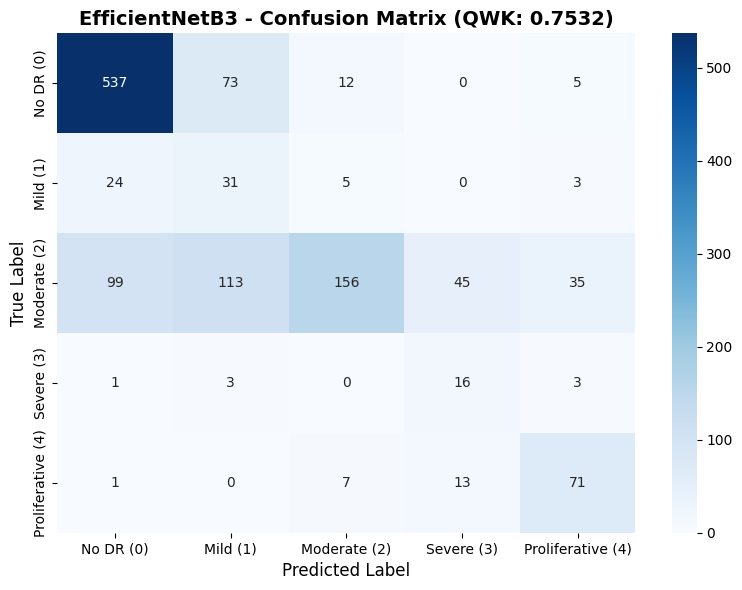

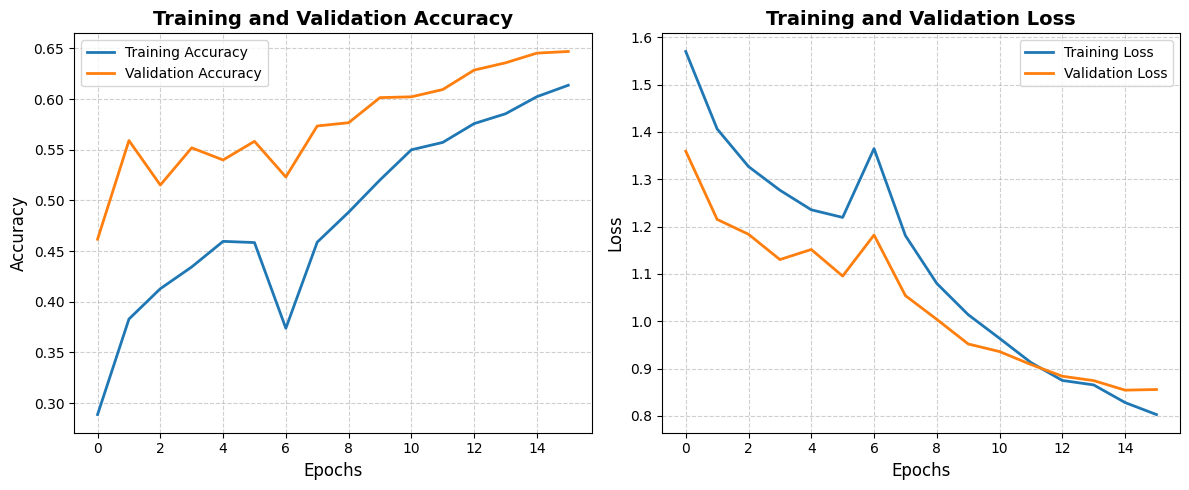

Graphs successfully generated and saved as PNG files!


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# ==========================================
# 1. GENERATE PREDICTIONS & METRICS
# ==========================================
print("Generating evaluation metrics and graphs...")
model.load_weights('best_effnet_model.keras')
test_generator.reset()

y_pred_probs = model.predict(test_generator, steps=len(test_generator), verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes

target_names = ["No DR (0)", "Mild (1)", "Moderate (2)", "Severe (3)", "Proliferative (4)"]

# ==========================================
# 2. CONFUSION MATRIX HEATMAP
# ==========================================
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('EfficientNetB3 - Confusion Matrix (QWK: 0.7532)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

# ==========================================
# 3. TRAINING HISTORY CURVES (Stage 1 & 2 combined or Stage 2)
# ==========================================
# Combining histories if both ran
acc = history_stage1.history['accuracy'] + history_stage2.history['accuracy']
val_acc = history_stage1.history['val_accuracy'] + history_stage2.history['val_accuracy']
loss = history_stage1.history['loss'] + history_stage2.history['loss']
val_loss = history_stage1.history['val_loss'] + history_stage2.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', linewidth=2)
plt.title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', linewidth=2)
plt.title('Training and Validation Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('training_history_curves.png', dpi=300)
plt.show()

print("Graphs successfully generated and saved as PNG files!")